# Wetland Mapping with TropWet: How Sensitive Are the Results to the Endmembers?

*Section 13 — Case study: wetland mapping (TropWet), notebook 6 of 6.* Previous: `05_mesma_and_comparison`. Next: none — this is the last notebook of the tutorials.

Notebooks 04 and 05 showed that *other* endmembers (from the corners of the data cloud, or from a spectral library) give quite different wetland maps. This notebook asks a narrower question: **how sensitive is the published method itself to how its endmembers are selected?** TropWet takes each endmember as the mean of the pixels passing an NDVI / MNDWI rule, so two things can change the endmembers:

1. **which pixels are averaged** (the sample): another image date, cloud mask or subset gives other pure pixels. A **bootstrap** of the pure pixels measures this.
2. **the rule thresholds**: MNDWI > 0.5 for water, NDVI > 0.7 for vegetation and the narrow NDVI / MNDWI window for sand were set in Barotseland, Zambia. A **one-at-a-time** scan and a **global (Sobol) sensitivity analysis** measure this.

The answer is given for the class areas (and the wetland area: Open Water + Emergent Flooded Vegetation + Wet Bare Sand), for every pixel (how often it keeps its class) and is finally compared with the spread between the endmember *methods* of notebooks 02, 04 and 05.

The analysis needs hundreds of unmixing runs, so it holds the composite (6 bands, 767 x 900 pixels) in memory and runs FCLS as a **tile graph** (`spec_unmix_fcls_node` and a `MemorySink`, about half a second per run) instead of writing every result to a file.

**You will learn:**
- how to run a method many times efficiently with `spec_unmix_fcls_node` and `TileGraph`;
- how to bootstrap the endmember selection, and summarise the class areas and per-pixel class stability;
- how to run a one-at-a-time and a variance-based (Sobol) sensitivity analysis of the selection rules with SALib;
- how to put the sensitivity of a method in context with the differences between methods.

**Before you start:** run notebooks 01–05 (section 8 reads their classifications).

**Data:** `outputs/inputs/` (the composite and its indices) and the classifications of notebooks 02, 04 and 05. Outputs are written to `outputs/sensitivity/`.

**Run time:** ~6 minutes.

## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook can be browsed online without having to run the notebook for it to make sense.

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_

## 1. Import Modules

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from SALib.analyze import sobol as sobol_analyze
from SALib.sample import sobol as sobol_sample

import rsgispy
import rsgispy.imagespectral.endmembers as spec_em
from rsgispy.imageprocess import MemorySink, RasterSource, TileGraph
from rsgispy.imagespectral.unmixing import spec_unmix_fcls_node
from rsgispy.mapping.layout import MapPanel, create_map_panels

## 2. Define Input Data and Directories

In [2]:
in_dir = os.path.join("outputs", "inputs")
em_dir = os.path.join("outputs", "endmembers")
unmix_dir = os.path.join("outputs", "unmixing")
sens_dir = os.path.join("outputs", "sensitivity")
os.makedirs(sens_dir, exist_ok=True)

comp_img = os.path.join(in_dir, "sref_composite.tif")
idx_img = os.path.join(in_dir, "composite_indices.tif")
band_names = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"]
em_names = ["Water", "Vegetation", "Sand"]
pxl_ha = 0.09  # 30 m pixels
rnd_seed = 42

# The composite and its indices, in memory.
with rasterio.open(comp_img) as src:
    comp = src.read().astype(np.float64)
    comp_profile = src.profile
with rasterio.open(idx_img) as src:
    ndvi, mndwi = src.read(1), src.read(2)
comp_vld = np.all(comp > 0, axis=0)
print(f"{comp_vld.sum()} valid pixels")

690300 valid pixels


## 3. The Published Method as Fast Functions

The functions below repeat the published method of notebooks 01 and 02 on arrays:

- `select_pure_pxls` applies the NDVI / MNDWI rules (1 = water, 2 = vegetation, 3 = sand; water is tested first, as in notebook 01);
- `mean_spectra` averages the composite over the pure pixels of each endmember (optionally only over a given sample of them);
- `unmix_fcls` runs FCLS in memory with a tile graph;
- `classify_tropwet` applies the TropWet class rules (Hardy et al., 2020, Table 3) to the fractions.

The rules are parameterised by the four thresholds varied below: the water MNDWI threshold, the vegetation NDVI threshold, and the centre and width of the sand NDVI window (published: 0.165 and 0.01, i.e. 0.16 < NDVI < 0.17; the sand MNDWI limits, −0.28 and 0.26, are kept).

In [3]:
PUBLISHED = {"water_mndwi": 0.5, "veg_ndvi": 0.7, "sand_ndvi_centre": 0.165,
             "sand_ndvi_width": 0.01}


def select_pure_pxls(water_mndwi=0.5, veg_ndvi=0.7, sand_ndvi_centre=0.165,
                     sand_ndvi_width=0.01):
    """TropWet pure pixel rules: 1 = water, 2 = vegetation, 3 = sand, 0 = not pure."""
    half = sand_ndvi_width / 2
    water = mndwi > water_mndwi
    veg = ndvi > veg_ndvi
    sand = ((ndvi > sand_ndvi_centre - half) & (ndvi < sand_ndvi_centre + half)
            & (mndwi > -0.28) & (mndwi < 0.26))
    pure = np.select([water, veg, sand], [1, 2, 3], default=0).astype(np.uint8)
    pure[~comp_vld | (ndvi < -1)] = 0
    return pure


def mean_spectra(pure, samples=None):
    """Mean composite spectrum of each endmember's pure pixels (or of ``samples``,
    a dict of pixel indices into each endmember's pure pixels)."""
    cols = {}
    for val, name in enumerate(em_names, start=1):
        pxls = comp[:, pure == val]
        if samples is not None and name in samples:
            pxls = pxls[:, samples[name]]
        cols[name] = pxls.mean(axis=1) if pxls.shape[1] else np.full(6, np.nan)
    return pd.DataFrame(cols, index=pd.Index(band_names, name="band"))


def unmix_fcls(em_df):
    """FCLS fractions (3, rows, cols) of the composite, in memory (no data -9999)."""
    node = spec_unmix_fcls_node(RasterSource(comp_img), em_df)
    return TileGraph(MemorySink(node, name="fracs")).run(use_pbar=False)["fracs"]


CLS = {1: "OW", 2: "EFV", 3: "WBS", 4: "GV", 5: "DSV", 6: "DBS", 7: "Other"}
WET = ["OW", "EFV", "WBS"]


def classify_tropwet(fracs, hi=75, lo=25):
    """TropWet class rules on fractions (0 = no data)."""
    w_pct, v_pct, s_pct = (100 * fracs.astype(np.float64))
    rules = [
        (1, w_pct >= hi),
        (2, (w_pct + v_pct >= hi) & (v_pct >= lo) & (v_pct < hi) & (w_pct >= lo) & (w_pct < hi)),
        (3, (w_pct + s_pct >= hi) & (w_pct >= lo) & (w_pct < hi) & (s_pct >= lo) & (s_pct < hi)),
        (4, v_pct >= hi),
        (5, (v_pct + s_pct >= hi) & (v_pct >= lo) & (v_pct < hi) & (s_pct >= lo) & (s_pct < hi)),
        (6, s_pct >= hi),
    ]
    cls_arr = np.select([r for _, r in rules], [c for c, _ in rules], default=7).astype(np.uint8)
    cls_arr[fracs[0] == -9999] = 0
    return cls_arr


def class_areas(cls_arr):
    """Area (ha) of each class and of the three wetland classes together."""
    areas = pd.Series({name: pxl_ha * np.sum(cls_arr == val) for val, name in CLS.items()})
    areas["wetland"] = areas[WET].sum()
    return areas

### 3.1 Check: do the functions reproduce the published result?

The classification from these functions is compared with the published classification written by notebook 02.

In [4]:
start = time.perf_counter()
pure_pub = select_pure_pxls(**PUBLISHED)
em_pub = mean_spectra(pure_pub)
fracs_pub = unmix_fcls(em_pub)
cls_pub = classify_tropwet(fracs_pub)
print(f"One run of the method: {time.perf_counter() - start:.2f} s")

with rasterio.open(os.path.join(unmix_dir, "composite_tropwet_classes.tif")) as src:
    cls_nb02 = src.read(1)
em_nb01 = spec_em.read_endmembers_df(os.path.join(em_dir, "endmembers_tropwet.csv"))
print("Largest difference from the notebook 01 endmembers:",
      float(np.abs(em_pub.to_numpy() - em_nb01.to_numpy()).max()))
vld = cls_pub > 0
print(f"Same class as notebook 02: {100 * np.mean(cls_pub[vld] == cls_nb02[vld]):.3f} % of pixels")
print("Pure pixels:", {name: int(np.sum(pure_pub == val)) for val, name in enumerate(em_names, 1)})
areas_pub = class_areas(cls_pub)
areas_pub.round(0)

One run of the method: 0.49 s
Largest difference from the notebook 01 endmembers: 0.0
Same class as notebook 02: 100.000 % of pixels
Pure pixels: {'Water': 179686, 'Vegetation': 325297, 'Sand': 181}


OW         15611.0
EFV         2609.0
WBS         1399.0
GV         33341.0
DSV         8113.0
DBS          475.0
Other        581.0
wetland    19618.0
dtype: float64

The functions reproduce the published result exactly: the endmembers are identical to those of notebook 01 and every pixel has the class of notebook 02. Any difference below is therefore due to the endmember selection, not to the implementation. One run takes about half a second, so hundreds of runs are practical.

Note how unbalanced the pure pixels are: about 180,000 water and 325,000 vegetation pixels, but only 181 sand pixels, because the sand window (0.16 < NDVI < 0.17) is very narrow.

## 4. Which Pixels? A Bootstrap of the Pure Pixels

A **bootstrap** resamples the pure pixels of every endmember with replacement (as many as there are), recomputes the mean spectra and reruns the method. The spread of the results over 100 resamples is the uncertainty due to *which* pure pixels were found, with the rules fixed.

In [5]:
n_boot = 100
rng = np.random.default_rng(rnd_seed)
n_pure = {name: int(np.sum(pure_pub == val)) for val, name in enumerate(em_names, 1)}

boot_areas, boot_ems = [], []
cls_counts = np.zeros((8,) + cls_pub.shape, dtype=np.uint16)  # votes for class 0-7
frac_sum = np.zeros(fracs_pub.shape)
frac_sq = np.zeros(fracs_pub.shape)
start = time.perf_counter()
for _ in range(n_boot):
    samples = {name: rng.integers(0, n, n) for name, n in n_pure.items()}
    em_df = mean_spectra(pure_pub, samples)
    fracs = unmix_fcls(em_df)
    cls_arr = classify_tropwet(fracs)
    boot_areas.append(class_areas(cls_arr))
    boot_ems.append(em_df)
    for val in range(8):
        cls_counts[val] += cls_arr == val
    frac_sum += np.where(fracs == -9999, 0, fracs)
    frac_sq += np.where(fracs == -9999, 0, fracs) ** 2
print(f"{n_boot} runs in {time.perf_counter() - start:.0f} s")

boot_df = pd.DataFrame(boot_areas)
boot_summary = pd.DataFrame({
    "published (ha)": areas_pub,
    "mean (ha)": boot_df.mean(),
    "2.5 % (ha)": boot_df.quantile(0.025),
    "97.5 % (ha)": boot_df.quantile(0.975),
    "CV (%)": 100 * boot_df.std() / boot_df.mean(),
})
boot_summary.round(1)

100 runs in 47 s


,published (ha),mean (ha),2.5 % (ha),97.5 % (ha),CV (%)
OW,15610.8,15606.2,15437.7,15806.1,0.8
EFV,2608.6,2607.9,2578.9,2654.9,0.8
WBS,1398.6,1398.1,1229.5,1546.8,7.3
GV,33340.6,33351.3,32573.6,33866.3,1.2
DSV,8112.6,8015.7,7759.2,8185.2,1.9
DBS,474.6,568.2,417.0,1121.1,37.8
Other,581.2,579.6,524.4,652.2,7.1
wetland,19618.0,19612.2,19550.6,19704.6,0.2


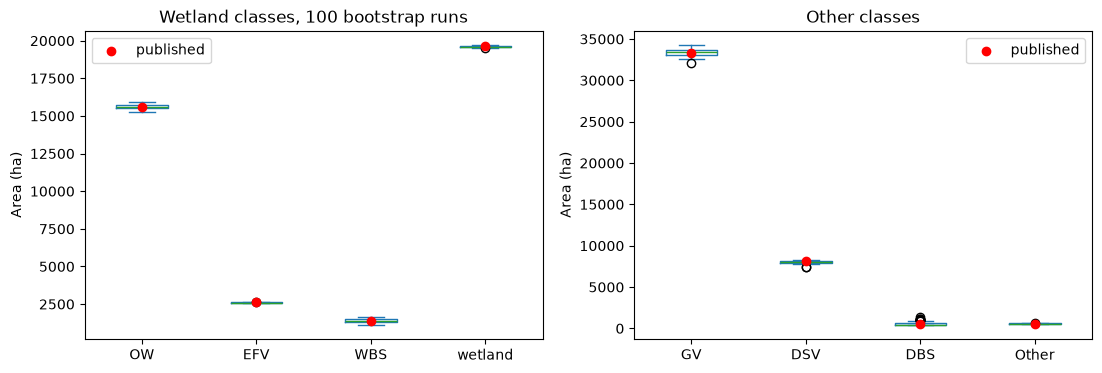

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
boot_df[WET + ["wetland"]].plot.box(ax=axs[0], ylabel="Area (ha)",
                                    title="Wetland classes, 100 bootstrap runs")
boot_df[["GV", "DSV", "DBS", "Other"]].plot.box(ax=axs[1], ylabel="Area (ha)",
                                                title="Other classes")
for ax, cols in zip(axs, (WET + ["wetland"], ["GV", "DSV", "DBS", "Other"])):
    ax.scatter(range(1, len(cols) + 1), areas_pub[cols], color="red", zorder=3,
               label="published")
    ax.legend()
plt.show()

The class areas hardly change when other pure pixels are drawn: the CV is 1–2 % for OW, EFV, GV and DSV, and the total wetland area varies by only 0.2 % (95 % range 19,551–19,705 ha around the published 19,618 ha). The two exceptions are **WBS** (CV 7 %, 1,230–1,547 ha) and above all **DBS** (CV 38 %, 417–1,121 ha), the two classes defined by the sand fraction. The DBS distribution is skewed (mean 568 ha against 475 ha published): a few resamples give a sand endmember that moves part of the DSV to DBS (the mean DSV area falls by about the same amount).

### 4.1 Which endmember's sample matters?

The bootstrap is repeated three times, each time resampling only one endmember's pure pixels and keeping the published mean for the others. The coefficient of variation (CV) of each class area then shows which endmember's sample drives the uncertainty.

In [7]:
oat_boot = {}
for name in em_names:
    areas_list = []
    for _ in range(30):
        samples = {name: rng.integers(0, n_pure[name], n_pure[name])}
        areas_list.append(class_areas(classify_tropwet(unmix_fcls(mean_spectra(pure_pub, samples)))))
    df = pd.DataFrame(areas_list)
    oat_boot[f"{name} resampled"] = 100 * df.std() / df.mean()
pd.DataFrame(oat_boot).round(2).rename_axis("CV of the area (%)")

,Water resampled,Vegetation resampled,Sand resampled
CV of the area (%),,,
OW,0.02,0.00,0.51
EFV,0.02,0.19,0.58
WBS,0.23,0.01,4.76
GV,0.00,0.02,0.82
DSV,0.00,0.07,1.31
DBS,0.05,0.80,28.46
Other,0.03,0.11,4.87
wetland,0.00,0.03,0.16


The sample of the **sand** endmember drives almost all of the variation (DBS CV 28 %, WBS and Other 5 %); resampling the water or vegetation pixels changes no area by more than 1 %. This is the effect of the sample sizes: the mean of 180,000 or 325,000 pixels hardly changes when they are resampled, the mean of 181 pixels does. When the method is applied elsewhere, the number of sand pixels passing the rule is a useful warning sign.

### 4.2 Which pixels keep their class?

`cls_counts` holds, for every pixel, how many of the 100 runs gave each class. The share of runs with the most common class measures how **stable** a pixel's class is, and the standard deviation of the fractions how much the fractions themselves move.

In [8]:
stability = cls_counts.max(axis=0) / n_boot
frac_sd = np.sqrt(np.maximum(frac_sq / n_boot - (frac_sum / n_boot) ** 2, 0))

profile = comp_profile.copy()
profile.update(count=4, dtype="float32", nodata=-1)
sens_img = os.path.join(sens_dir, "bootstrap_stability_fraction_sd.tif")
out = np.stack([stability, *frac_sd]).astype(np.float32)
out[:, ~(cls_pub > 0)] = -1
with rasterio.open(sens_img, "w", **profile) as dst:
    dst.write(out)
    dst.descriptions = ("class_stability", "water_sd", "vegetation_sd", "sand_sd")

vld = cls_pub > 0
print(f"Pixels with the same class in all {n_boot} runs: {100 * np.mean(stability[vld] == 1):.1f} %")
print(f"Pixels with the same class in fewer than 90 % of the runs: "
      f"{100 * np.mean(stability[vld] < 0.9):.1f} %")
pd.Series({CLS[val]: 100 * np.mean(stability[cls_pub == val] < 0.9) for val in CLS},
          name="% of the class's pixels with < 90 % stability").round(1)

Pixels with the same class in all 100 runs: 92.1 %
Pixels with the same class in fewer than 90 % of the runs: 3.8 %


OW        0.9
EFV       1.2
WBS      17.5
GV        1.7
DSV      12.5
DBS      34.8
Other    33.4
Name: % of the class's pixels with < 90 % stability, dtype: float64

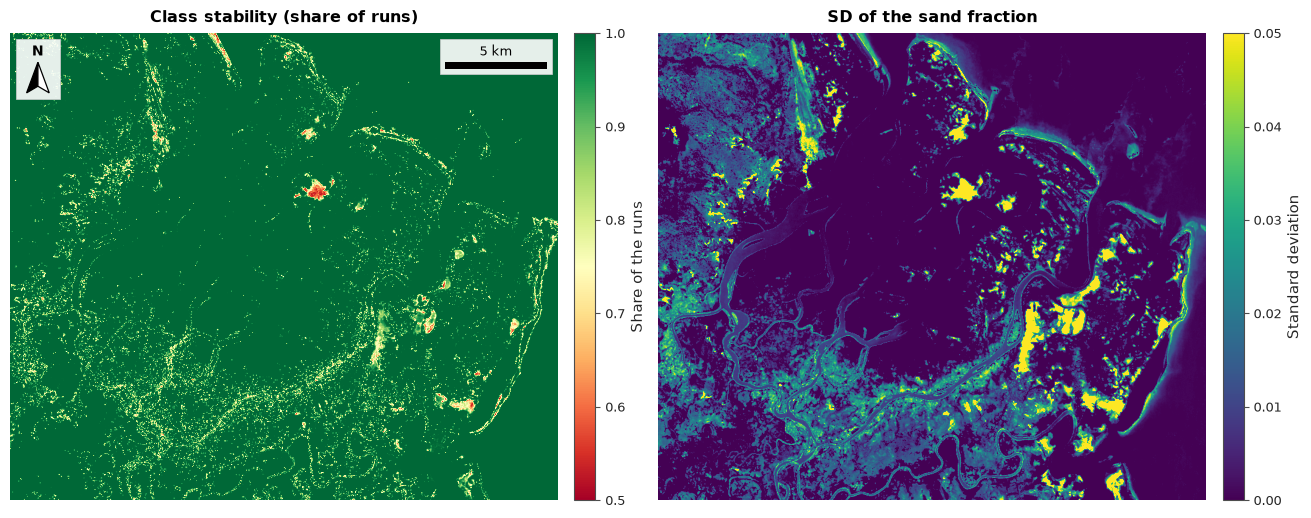

In [9]:
fig, axs = create_map_panels(
    [
        MapPanel("cmap", sens_img, bands=1, title="Class stability (share of runs)",
                 cmap_name="RdYlGn", vmin=0.5, vmax=1, show_colour_bar=True,
                 cbar_label="Share of the runs"),
        MapPanel("cmap", sens_img, bands=4, title="SD of the sand fraction",
                 cmap_name="viridis", vmin=0, vmax=0.05, show_colour_bar=True,
                 cbar_label="Standard deviation"),
    ],
    figsize=(13, 5.5),
)

92 % of the pixels have the same class in all 100 runs and only 3.8 % in fewer than 90 % of the runs. The unstable pixels are not spread at random: they are the pixels with a large sand fraction (the sand fraction SD map), i.e. the DBS (35 % of its pixels below 90 % stability), Other (33 %), WBS (18 %) and DSV (13 %) classes, mainly the bare fields and the beach ridges in the east and the mud flats along the coast. The open water, the mangroves and the dense vegetation (≤ 2 %) are stable.

## 5. Which Rules? One Threshold at a Time

Each of the four thresholds is now varied over a plausible range with the others at their published values. For each value the pure pixels are reselected, the endmembers recomputed and the method rerun.

In [10]:
oat_ranges = {
    "water_mndwi": np.round(np.arange(0.3, 0.71, 0.05), 3),
    "veg_ndvi": np.round(np.arange(0.55, 0.86, 0.05), 3),
    "sand_ndvi_centre": np.round(np.arange(0.10, 0.251, 0.025), 3),
    "sand_ndvi_width": np.array([0.005, 0.01, 0.02, 0.03, 0.04, 0.05]),
}
oat_results = []
for param, values in oat_ranges.items():
    for value in values:
        thres = {**PUBLISHED, param: float(value)}
        pure = select_pure_pxls(**thres)
        counts = {f"n_{name}": int(np.sum(pure == val)) for val, name in enumerate(em_names, 1)}
        if min(counts.values()) == 0:
            continue  # no pure pixels for an endmember: the method cannot run
        areas = class_areas(classify_tropwet(unmix_fcls(mean_spectra(pure))))
        oat_results.append({"parameter": param, "value": float(value), **counts, **areas})
oat_df = pd.DataFrame(oat_results)
oat_df[["parameter", "value", "n_Water", "n_Vegetation", "n_Sand"] + WET + ["wetland"]].round(
    {"value": 3, **{col: 0 for col in oat_df.columns if col not in ("parameter", "value")}}
)

,parameter,value,n_Water,n_Vegetation,n_Sand,OW,EFV,WBS,wetland
0,water_mndwi,0.300,186556,325297,181,15724.0,2628.0,1301.0,19653.0
1,water_mndwi,0.350,185150,325297,181,15693.0,2622.0,1325.0,19640.0
2,water_mndwi,0.400,183658,325297,181,15663.0,2618.0,1352.0,19633.0
3,water_mndwi,0.450,182104,325297,181,15636.0,2614.0,1375.0,19625.0
4,water_mndwi,0.500,179686,325297,181,15611.0,2609.0,1399.0,19618.0
5,water_mndwi,0.550,176273,325297,181,15585.0,2603.0,1423.0,19611.0
6,water_mndwi,0.600,170057,325297,181,15566.0,2597.0,1439.0,19602.0
7,water_mndwi,0.650,157680,325297,181,15559.0,2594.0,1441.0,19594.0
8,water_mndwi,0.700,124852,325297,181,15576.0,2592.0,1418.0,19585.0
9,veg_ndvi,0.550,179686,430017,181,15613.0,2759.0,1406.0,19778.0


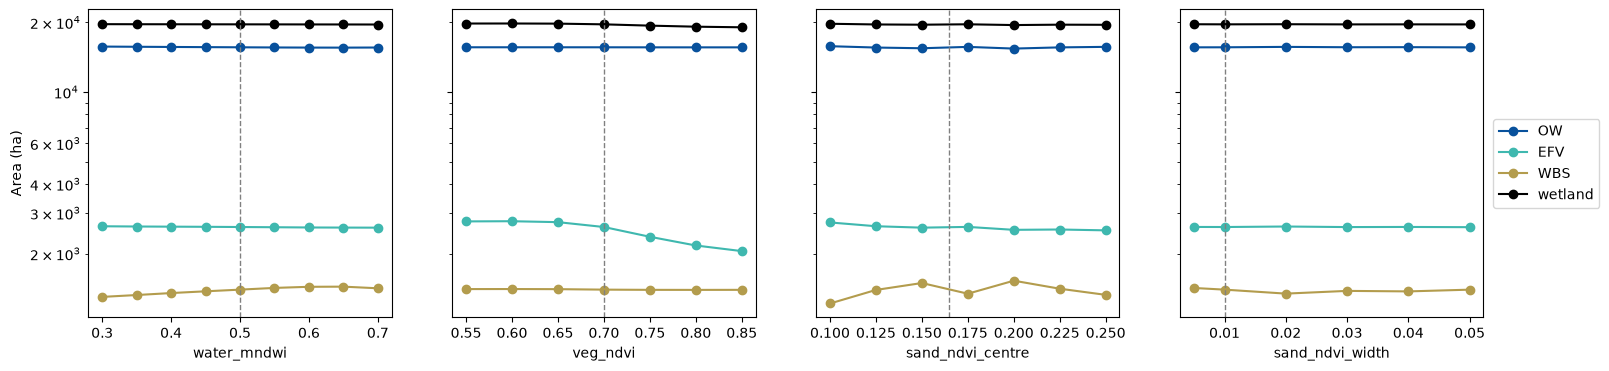

In [11]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (param, grp) in zip(axs, oat_df.groupby("parameter", sort=False)):
    for cls_name, colour in zip(WET + ["wetland"], ["#08519C", "#3FB8AF", "#B39C4D", "black"]):
        ax.plot(grp["value"], grp[cls_name], marker="o", color=colour, label=cls_name)
    ax.axvline(PUBLISHED[param], color="grey", ls="--", lw=1)
    ax.set_xlabel(param)
    ax.set_yscale("log")
axs[0].set_ylabel("Area (ha)")
axs[-1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

Each threshold acts on the classes of its own endmember, and the effects are modest within these ranges:

- **Water MNDWI** (0.3–0.7): OW changes by 165 ha (1 %) and WBS by 140 ha (1,301–1,441 ha); a stricter threshold keeps the clearer water, so more of the turbid water and mud become WBS.
- **Vegetation NDVI** (0.55–0.85) has the largest effect: EFV falls from 2,764 to 2,052 ha as the threshold rises (the vegetation endmember changes the split between vegetation and water in the mangrove pixels), and the wetland area changes by 730 ha (19,050–19,784 ha).
- **Sand NDVI centre** (0.10–0.25) gives the noisiest response (WBS 1,218–1,529 ha, without a trend): each centre selects a different set of only ~160–210 pixels, so this is the small sample of section 4.1 again.
- **Sand NDVI width** (0.005–0.05) changes the number of sand pixels from 89 to 854, but no area by more than 4 %: widening the window adds pixels similar to those already selected.

A one-at-a-time scan keeps the other thresholds at their published values, so it cannot show whether two thresholds together matter more than each alone.

## 6. All Rules Together: a Sobol Sensitivity Analysis

The one-at-a-time scan misses interactions (e.g. a lower vegetation threshold matters more when the sand window is wide). A **variance-based (Sobol) sensitivity analysis** varies all four thresholds together over the same ranges and splits the variance of each output into the contributions of each threshold:

- **S1 (first order):** the share of the variance due to the threshold alone;
- **ST (total order):** the share including all its interactions with the other thresholds.

SALib (Herman & Usher, 2017) draws a Saltelli / Sobol sample of the thresholds (64 base samples, giving 64 x (4 + 2) = 384 runs) and computes the indices with bootstrap confidence intervals (`_conf`). Runs where an endmember has no pure pixels are given the published result (they are rare in these ranges, and the count is printed).

In [12]:
problem = {
    "num_vars": 4,
    "names": list(PUBLISHED),
    "bounds": [[0.3, 0.7], [0.55, 0.85], [0.10, 0.25], [0.005, 0.05]],
}
param_sets = sobol_sample.sample(problem, 64, calc_second_order=False, seed=rnd_seed)
print(f"{len(param_sets)} runs")

sobol_rows, n_empty = [], 0
start = time.perf_counter()
for values in param_sets:
    pure = select_pure_pxls(**dict(zip(problem["names"], values)))
    if min(np.sum(pure == val) for val in (1, 2, 3)) == 0:
        n_empty += 1
        sobol_rows.append(areas_pub)
        continue
    sobol_rows.append(class_areas(classify_tropwet(unmix_fcls(mean_spectra(pure)))))
print(f"{time.perf_counter() - start:.0f} s; {n_empty} runs without pure pixels for an endmember")
sobol_df = pd.DataFrame(sobol_rows)
sobol_df.to_csv(os.path.join(sens_dir, "sobol_runs.csv"), index=False)
sobol_df[WET + ["wetland"]].describe().round(0)

384 runs


177 s; 0 runs without pure pixels for an endmember


,OW,EFV,WBS,wetland
count,384.0,384.0,384.0,384.0
mean,15622.0,2499.0,1380.0,19502.0
std,81.0,265.0,68.0,271.0
min,15308.0,1897.0,1209.0,18900.0
25%,15561.0,2254.0,1335.0,19253.0
50%,15622.0,2594.0,1381.0,19594.0
75%,15679.0,2728.0,1432.0,19734.0
max,15826.0,2850.0,1693.0,19886.0


In [13]:
sobol_idx = {}
for output in WET + ["wetland", "GV", "DSV"]:
    res = sobol_analyze.analyze(problem, sobol_df[output].to_numpy(), calc_second_order=False,
                                seed=rnd_seed)
    sobol_idx[output] = pd.DataFrame(
        {"S1": res["S1"], "ST": res["ST"], "ST_conf": res["ST_conf"]}, index=problem["names"]
    )
sobol_tbl = pd.concat(sobol_idx, axis=1)
sobol_tbl.round(2)

OW                 EFV                 WBS                \
                    S1    ST ST_conf    S1    ST ST_conf    S1    ST ST_conf   
water_mndwi       0.44  0.36    0.14  0.00  0.00    0.00  0.43  0.38    0.16   
veg_ndvi         -0.00  0.01    0.00  0.88  0.90    0.25  0.00  0.00    0.00   
sand_ndvi_centre  0.30  0.43    0.20  0.04  0.04    0.02  0.28  0.39    0.21   
sand_ndvi_width  -0.00  0.15    0.09  0.01  0.00    0.00  0.00  0.15    0.10   

                 wetland                  GV                 DSV                
                      S1    ST ST_conf    S1    ST ST_conf    S1    ST ST_conf  
water_mndwi         0.01  0.01    0.00  0.00  0.00    0.00  0.00  0.00    0.00  
veg_ndvi            0.88  0.90    0.25  0.86  0.85    0.21  0.87  0.87    0.22  
sand_ndvi_centre    0.02  0.04    0.02  0.03  0.03    0.01  0.01  0.02    0.01  
sand_ndvi_width     0.01  0.00    0.00 -0.01  0.00    0.00 -0.01  0.00    0.00

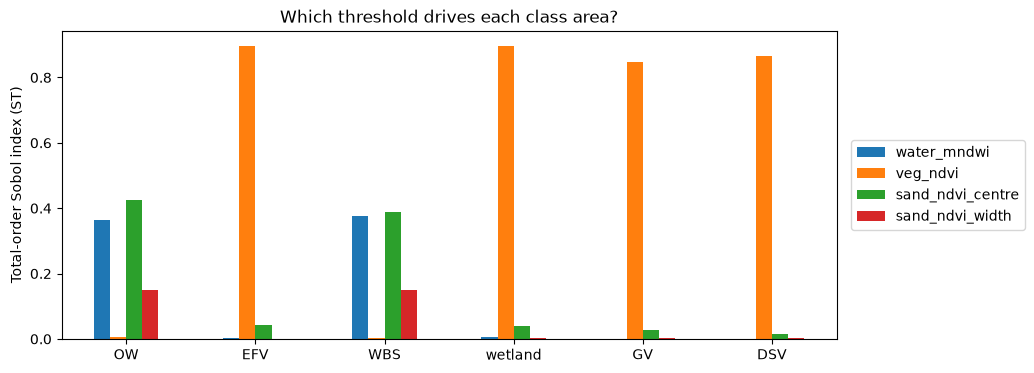

In [14]:
st_df = pd.DataFrame({out: idx["ST"] for out, idx in sobol_idx.items()})
ax = st_df.T.plot.bar(figsize=(10, 4), rot=0, ylabel="Total-order Sobol index (ST)",
                      title="Which threshold drives each class area?")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

With all four thresholds varied together, the wetland area ranges from 18,900 to 19,886 ha (EFV 1,897–2,850 ha), similar to the one-at-a-time ranges. The indices show which threshold is responsible:

- **The vegetation NDVI threshold dominates** EFV, the wetland area, GV and DSV (ST ≈ 0.85–0.90): it alone explains almost all of their variance, with little interaction (S1 ≈ ST).
- **OW and WBS** depend on the **water MNDWI threshold** (ST ≈ 0.37) and the **sand NDVI centre** (ST ≈ 0.4); the sand width matters only through interactions (S1 ≈ 0, ST ≈ 0.15). Their confidence intervals are wide (±0.15–0.2), because the response to the sand centre is noisy rather than smooth; 64 base samples are enough to rank the thresholds, not to give precise indices (an S1 slightly above ST, or slightly below 0, is estimation error).

For a TropWet user, the vegetation threshold is therefore the one to check when the wetland area matters; the water and sand thresholds matter for the split between open water and wet bare sand.

## 7. Putting It in Context: Sensitivity vs Choice of Method

Finally, the spread within the published method (the bootstrap and the Sobol runs over the threshold ranges) is compared with the differences between the endmember methods of the previous notebooks, read from their classifications.

In [15]:
method_imgs = {
    "published (nb 02)": os.path.join(unmix_dir, "composite_tropwet_classes.tif"),
    "bright sand (nb 02)": os.path.join(unmix_dir, "composite_bright_classes.tif"),
    "two-model MESMA (nb 02)": os.path.join(unmix_dir, "composite_mesma_classes.tif"),
    "VCA (nb 04)": os.path.join("outputs", "extraction", "composite_vca_classes.tif"),
    "N-FINDR (nb 04)": os.path.join("outputs", "extraction", "composite_nfindr_classes.tif"),
    "PPI (nb 04)": os.path.join("outputs", "extraction", "composite_ppi_classes.tif"),
    "MESMA EAR (nb 05)": os.path.join("outputs", "mesma", "mesma_ear_classes.tif"),
}
method_areas = {}
for name, img in method_imgs.items():
    with rasterio.open(img) as src:
        method_areas[name] = class_areas(src.read(1))
method_df = pd.DataFrame(method_areas).T

context = pd.DataFrame({
    "published": areas_pub,
    "bootstrap 95 % range": boot_df.quantile(0.975) - boot_df.quantile(0.025),
    "thresholds 5–95 % range": sobol_df.quantile(0.95) - sobol_df.quantile(0.05),
    "methods range": method_df.max() - method_df.min(),
}).loc[WET + ["wetland", "GV", "DSV"]]
context.round(0)

,published,bootstrap 95 % range,thresholds 5–95 % range,methods range
OW,15611.0,368.0,245.0,1736.0
EFV,2609.0,76.0,740.0,38051.0
WBS,1399.0,317.0,206.0,1818.0
wetland,19618.0,154.0,779.0,39966.0
GV,33341.0,1293.0,7603.0,32568.0
DSV,8113.0,426.0,5980.0,19000.0


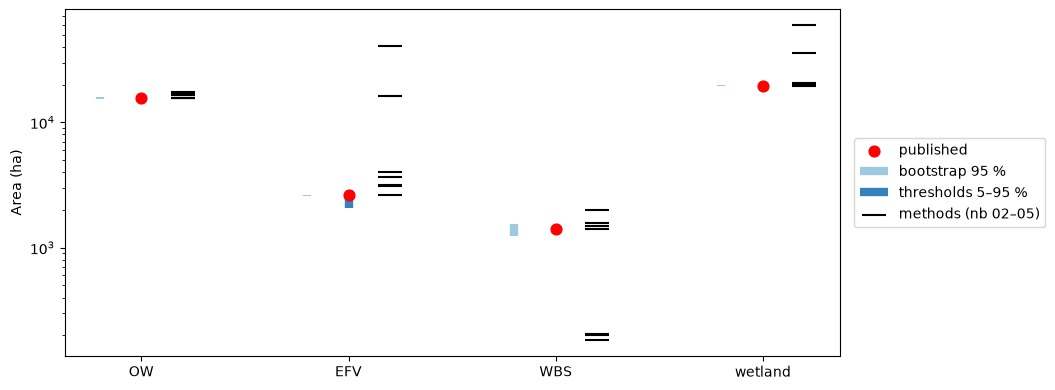

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cols = WET + ["wetland"]
x_pos = np.arange(len(cols))
ax.scatter(x_pos, areas_pub[cols], color="red", s=60, zorder=4, label="published")
for i, col in enumerate(cols):
    ax.vlines(i - 0.2, boot_df[col].quantile(0.025), boot_df[col].quantile(0.975), lw=6,
              color="#9ECAE1", label="bootstrap 95 %" if i == 0 else None)
    ax.vlines(i, sobol_df[col].quantile(0.05), sobol_df[col].quantile(0.95), lw=6,
              color="#3182BD", label="thresholds 5–95 %" if i == 0 else None)
    ax.scatter(np.full(len(method_df), i + 0.2), method_df[col], marker="_", s=300,
               color="black", label="methods (nb 02–05)" if i == 0 else None)
ax.set_xticks(x_pos, cols)
ax.set_yscale("log")
ax.set_ylabel("Area (ha)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

The figure (logarithmic axis) and the table compare three sources of variation in the wetland classes:

- the **bootstrap** (which pure pixels): tens to a few hundred hectares;
- the **thresholds** (the rules, varied over plausible ranges): up to ~800 ha for EFV and the wetland area, and several thousand hectares for GV and DSV;
- the **choice of endmember method** (notebooks 02–05: TropWet, bright sand, MESMA, VCA, N-FINDR, PPI): up to 38,000 ha for EFV and 40,000 ha for the wetland area, two orders of magnitude more.

So the published method is robust to its own endmember selection: another sample or slightly different thresholds give almost the same wetland map. Choosing the endmembers in a different way (from the image extremes, or from a library pruned to a different set of spectra) is what changes the result.

## 8. Summary

- Reimplementing the method as fast in-memory functions (exactly reproducing notebooks 01–02, ~0.5 s per run) makes sensitivity analyses with hundreds of runs practical.
- **A bootstrap of the pure pixels** measures the uncertainty due to the sample: the wetland area varies by only 0.2 %, but the sand classes (DBS 38 %, WBS 7 %) vary more, because the sand endmember is the mean of only 181 pixels. Resampling one endmember at a time identifies it as the cause.
- **Per-pixel stability** shows where the classification is uncertain: 92 % of the pixels never change class, and the unstable pixels are those with a large sand fraction.
- **One-at-a-time scans** and a **Sobol analysis** (SALib) of the four rule thresholds show that the vegetation NDVI threshold dominates EFV and the wetland area, while the water and sand thresholds control the split between OW and WBS; within plausible ranges the wetland area changes by less than 4 %.
- These effects are small compared with the **choice of endmember method** (notebooks 04–05), which changes the wetland area by up to a factor of three. Report how the endmembers were chosen, and check the sensitivity of a result to that choice before comparing maps made with different endmembers.

This is the last notebook of the TropWet case study and of the rsgispy tutorials.

**References**
- Hardy, A., Oakes, G., Ettritch, G. (2020). Tropical Wetland (TropWet) Mapping Tool: The Automatic Detection of Open and Vegetated Waterbodies in Google Earth Engine for Tropical Wetlands. *Remote Sensing*, 12(7), 1182. https://doi.org/10.3390/rs12071182
- Herman, J., Usher, W. (2017). SALib: An open-source Python library for sensitivity analysis. *Journal of Open Source Software*, 2(9), 97.
- Saltelli, A., Annoni, P., Azzini, I., Campolongo, F., Ratto, M., Tarantola, S. (2010). Variance based sensitivity analysis of model output. Design and estimator for the total sensitivity index. *Computer Physics Communications*, 181(2), 259–270.

Landsat data courtesy of the U.S. Geological Survey.